In [1]:
import pandas as pd
import numpy as np
import seaborn as sns


In [4]:
df = pd.read_csv("sales_data_sample.csv", encoding = "Latin-1") 
df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [6]:
df.dtypes
df.isna().sum()

ORDERNUMBER            0
QUANTITYORDERED        0
PRICEEACH              0
ORDERLINENUMBER        0
SALES                  0
ORDERDATE              0
STATUS                 0
QTR_ID                 0
MONTH_ID               0
YEAR_ID                0
PRODUCTLINE            0
MSRP                   0
PRODUCTCODE            0
CUSTOMERNAME           0
PHONE                  0
ADDRESSLINE1           0
ADDRESSLINE2        2521
CITY                   0
STATE               1486
POSTALCODE            76
COUNTRY                0
TERRITORY           1074
CONTACTLASTNAME        0
CONTACTFIRSTNAME       0
DEALSIZE               0
dtype: int64

In [8]:
#remove unnecessary columns
drop_cols = [
    "PRODUCTCODE" , "TERRITORY" , "ADDRESSLINE1", "ADDRESSLINE2" , "POSTALCODE" , "TERRITORY" , "CITY" , "STATE" , "COUNTRY" , "CUSTOMERNAME" , "CONTACTLASTNAME" , "CONTACTFIRSTNAME" , "PHONE"]

df.drop(columns = drop_cols , inplace = True , errors = "ignore")

In [11]:
df["ORDERDATE"] = pd.to_datetime(df["ORDERDATE"])
df["ORDERDATE"] = (
    df["ORDERDATE"] - df["ORDERDATE"].min()
).dt.days

In [15]:
#one hot encoding
df = pd.get_dummies(
    df , 
    columns = ["STATUS" , "PRODUCTLINE" , "DEALSIZE"],
    dtype = int
)

In [16]:
df = df.dropna()

In [20]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
dataset = scaler.fit_transform(df)

In [30]:
#elbow method
from sklearn.cluster import KMeans

WCSS=[]
for i in range( 1 ,11):
    kmeans = KMeans(
    n_clusters = i,
    random_state = 42,
    n_init = 10
)
    kmeans.fit(dataset)
    WCSS.append(kmeans.inertia_)
       

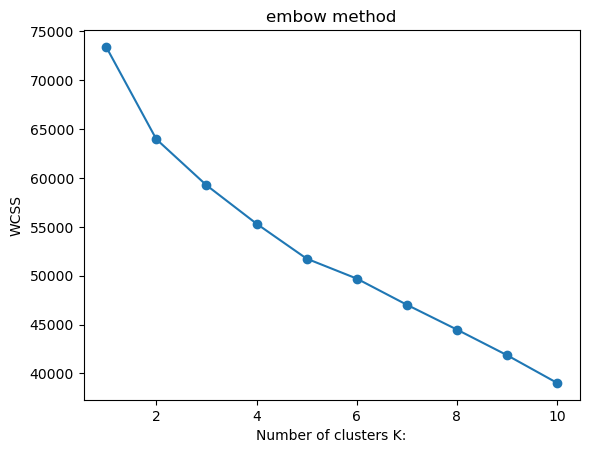

In [31]:
import matplotlib.pyplot as plt
plt.plot(range(1,11) , WCSS, marker = "o")
plt.xlabel("Number of clusters K:")
plt.ylabel("WCSS")
plt.title("embow method")
plt.show()